In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score


data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset loaded with {X.shape[0]} samples and {X.shape[1]} features.")

Dataset loaded with 569 samples and 30 features.


### **Step: 2 & 3: Compute Distances and Draw Dendrogram**

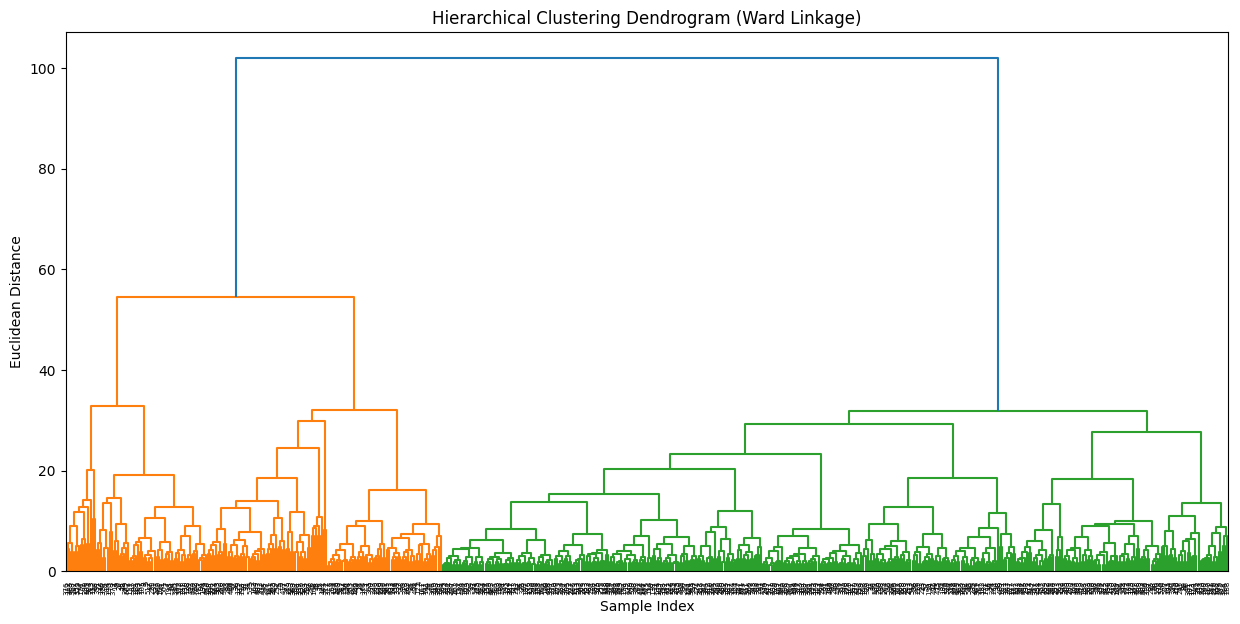

In [2]:
plt.figure(figsize=(15, 7))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")

linked = linkage(X_scaled, method='ward')
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
plt.show()

### **Step: 4 & 5: Compare Different Linkage Methods**

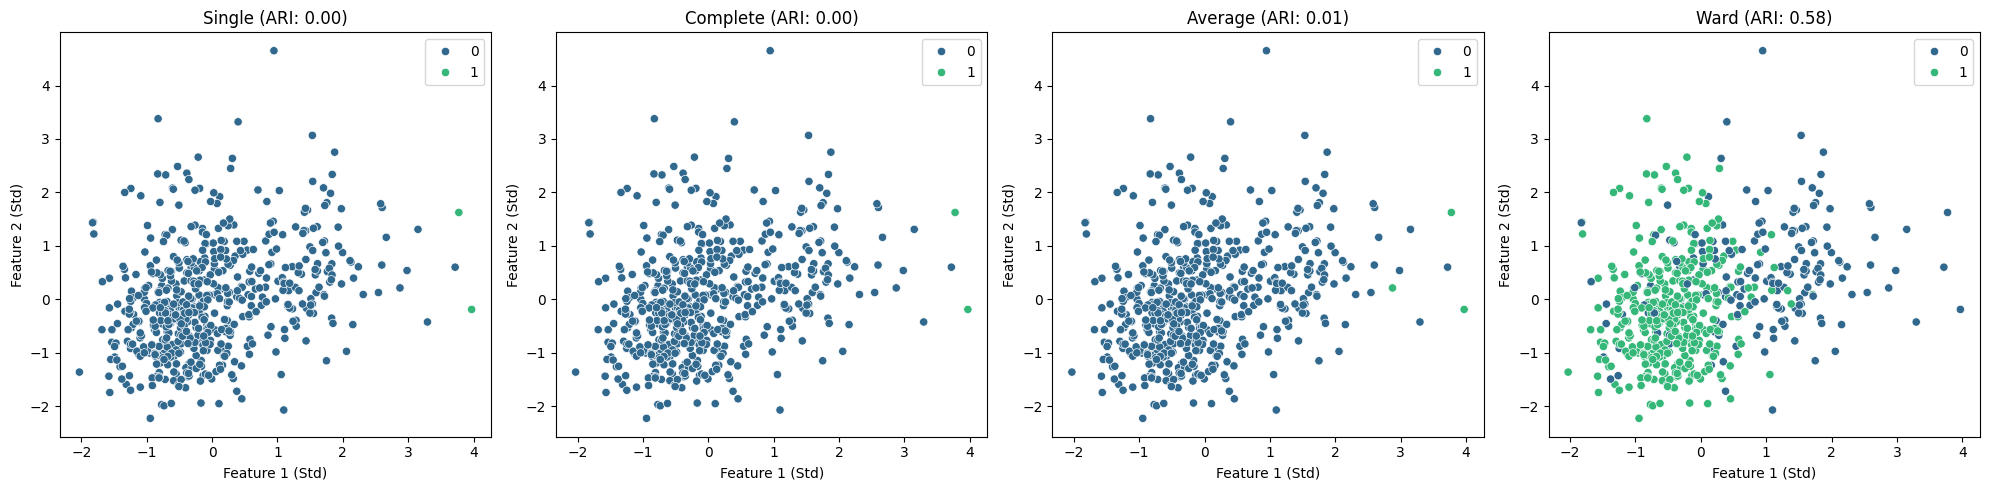

In [3]:
linkages = ['single', 'complete', 'average', 'ward']
results = {}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for i, link in enumerate(linkages):
    model = AgglomerativeClustering(n_clusters=2, linkage=link)
    clusters = model.fit_predict(X_scaled)
    results[link] = clusters


    score = adjusted_rand_score(y, clusters)

    sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=clusters, palette='viridis', ax=axes[i])
    axes[i].set_title(f"{link.capitalize()} (ARI: {score:.2f})")
    axes[i].set_xlabel("Feature 1 (Std)")
    axes[i].set_ylabel("Feature 2 (Std)")

plt.tight_layout()
plt.show()

### **Step 6: Cluster Interpretation**

In [4]:
df = pd.DataFrame(X, columns=feature_names)
df['Cluster'] = results['ward']

cluster_means = df.groupby('Cluster').mean()
display(cluster_means.T.head(10))

Cluster,0,1
mean radius,17.363033,12.580860
mean texture,21.316304,18.321065
mean perimeter,115.166739,80.882338
mean area,980.025000,499.499481
mean smoothness,0.105442,0.092020
mean compactness,0.160079,0.077703
mean concavity,0.179883,0.045268
mean concave points,0.093730,0.027503
mean symmetry,0.198155,0.173041
mean fractal dimension,0.065364,0.061571
